# 🏠 Real Estate Investment Advisor
### Predicting Property Profitability & Future Value

**Domain:** Real Estate / Investment / Financial Analytics  
**Tasks:** (1) Classify whether a property is a **Good Investment** · (2) Predict **Price after 5 years**

This notebook covers the full analytical pipeline from the project brief:

| Part | Content |
|---|---|
| 1 | Setup & data loading |
| 2 | Data quality checks (missing values, duplicates, validity, outliers) |
| 3 | Cleaning & feature engineering |
| 4 | Target creation (`Good_Investment`, `Future_Price_5Y`) |
| 5 | Exploratory Data Analysis – all 20 questions from the brief |
| 6 | Model preparation (encoding, scaling, train/test split) |
| 7 | Classification models + MLflow tracking |
| 8 | Regression models + MLflow tracking |
| 9 | Feature importance & saving artifacts for the Streamlit app |

>  **Important note on the targets.** The dataset has **no** column for "good investment" and **no** future price.
> Both targets are *engineered* from domain rules and explicit assumptions (see Part 4). Model scores therefore tell us how well
> the models learn those rules – **not** how real markets will behave. This should be stated clearly in the project documentation.

## Part 1 · Setup & Data Loading

In [64]:
import os, json, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance

# Optional libraries (the notebook still runs without them)
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    import mlflow, mlflow.sklearn
    HAS_MLFLOW = True
except ImportError:
    HAS_MLFLOW = False

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

RANDOM_STATE = 42
CURRENT_YEAR = 2025          # reference year used by the dataset's Age_of_Property
OUT_DIR = "outputs"          # cleaned data, models, metadata
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("models", exist_ok=True)

print(f"XGBoost available: {HAS_XGB} | MLflow available: {HAS_MLFLOW}")
if not HAS_XGB:
    print("  -> pip install xgboost   (HistGradientBoosting will be used instead)")
if not HAS_MLFLOW:
    print("  -> pip install mlflow    (experiment logging will be skipped)")

XGBoost available: False | MLflow available: False
  -> pip install xgboost   (HistGradientBoosting will be used instead)
  -> pip install mlflow    (experiment logging will be skipped)


In [65]:
candidates = ["india_housing_prices.csv", "data/india_housing_prices.csv",
              "/mnt/user-data/uploads/india_housing_prices.csv"]
DATA_PATH = "india_housing_prices.csv"
assert DATA_PATH, " india_housing_prices.csv not found."

raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## Part 2 · Data Quality Checks

In [66]:
df = raw.copy()

print("Missing values per column (total):", int(df.isna().sum().sum()))
print("Fully duplicated rows            :", int(df.drop(columns="ID").duplicated().sum()))
print("Duplicated IDs                   :", int(df["ID"].duplicated().sum()))
print()
df.info()

Missing values per column (total): 0
Fully duplicated rows            : 0
Duplicated IDs                   : 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status            

In [67]:
num_cols_raw = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built", "Floor_No",
                "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals"]
display(df[num_cols_raw].describe().T)

cat_cols_raw = ["State", "City", "Property_Type", "Furnished_Status", "Public_Transport_Accessibility",
                "Parking_Space", "Security", "Facing", "Owner_Type", "Availability_Status"]
pd.DataFrame({"unique values": df[cat_cols_raw].nunique(),
              "categories": [", ".join(map(str, sorted(df[c].unique())[:6])) + (" ..." if df[c].nunique() > 6 else "")
                             for c in cat_cols_raw]})

,count,mean,std,min,25%,50%,75%,max
BHK,"250,000.00",3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00","2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"
Floor_No,"250,000.00",14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,"250,000.00",15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,"250,000.00",18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,"250,000.00",5.50,2.88,1.00,3.00,5.00,8.00,10.00
Nearby_Hospitals,"250,000.00",5.50,2.87,1.00,3.00,5.00,8.00,10.00


,unique values,categories
State,20,"Andhra Pradesh, Assam, Bihar, Chhattisgarh, De..."
City,42,"Ahmedabad, Amritsar, Bangalore, Bhopal, Bhuban..."
Property_Type,3,"Apartment, Independent House, Villa"
Furnished_Status,3,"Furnished, Semi-furnished, Unfurnished"
Public_Transport_Accessibility,3,"High, Low, Medium"
Parking_Space,2,"No, Yes"
Security,2,"No, Yes"
Facing,4,"East, North, South, West"
Owner_Type,3,"Broker, Builder, Owner"
Availability_Status,2,"Ready_to_Move, Under_Construction"


### Validity checks
Beyond missing values and duplicates, we check whether the data is *logically* consistent.

In [68]:
checks = {
    "Floor_No > Total_Floors (impossible)":               (df["Floor_No"] > df["Total_Floors"]).mean(),
    "Age_of_Property != CURRENT_YEAR - Year_Built":      (df["Age_of_Property"] != CURRENT_YEAR - df["Year_Built"]).mean(),
    "Price_per_SqFt == 0 after rounding":                 (df["Price_per_SqFt"] == 0).mean(),
    "Size_in_SqFt <= 0":                                  (df["Size_in_SqFt"] <= 0).mean(),
    "Price_in_Lakhs <= 0":                                (df["Price_in_Lakhs"] <= 0).mean(),
}
pd.Series(checks).map("{:.2%}".format).to_frame("share of rows")

,share of rows
Floor_No > Total_Floors (impossible),46.52%
Age_of_Property != CURRENT_YEAR - Year_Built,0.00%
Price_per_SqFt == 0 after rounding,1.01%
Size_in_SqFt <= 0,0.00%
Price_in_Lakhs <= 0,0.00%


**Findings**

* No missing values and no duplicates – imputation is not needed (the code below is still written defensively).
* `Age_of_Property` is consistent with `Year_Built` (reference year 2025).
* **~46 % of rows have `Floor_No > Total_Floors`**, which is physically impossible. We cannot drop half the data, so we keep a flag
  (`Floor_Data_Inconsistent`) and cap `Floor_No` at `Total_Floors`.
* `Price_per_SqFt` is stored in **lakhs per sq ft rounded to 2 decimals**, so it loses almost all precision (many values are 0.0x).
  We recompute it in **₹ per sq ft** from price and size.

In [69]:
# --- outlier detection (IQR rule) on size, price and recomputed price per sq ft
df["Price_per_SqFt_calc"] = df["Price_in_Lakhs"] * 1e5 / df["Size_in_SqFt"]     # Rs per sq ft

def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_calc"]:
    lo, hi = iqr_bounds(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"feature": col, "lower": lo, "upper": hi, "outliers": n_out, "share": n_out / len(df)})
pd.DataFrame(rows).set_index("feature")

,lower,upper,outliers,share
feature,,,,
Size_in_SqFt,"-1,753.50","7,250.50",0,0.00
Price_in_Lakhs,-233.94,743.38,0,0.00
Price_per_SqFt_calc,"-11,973.98","32,764.21",19723,0.08


Size and price are bounded (500–5,000 sq ft, ₹10–500 lakhs) so they have **no outliers**. Price per sq ft does have IQR outliers, but they are *legitimate*
(small, cheap-per-area combinations like a 500 sq ft flat priced at ₹495 lakhs → ₹99,000/sq ft). We therefore **flag instead of delete**
and use `log` scale in the EDA plots.

## Part 3 · Cleaning & Feature Engineering

In [70]:
df = raw.copy()

# 1) Defensive cleaning (nothing is missing here, but the app/pipeline should be robust)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "ID"]).reset_index(drop=True)
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype(str).str.strip()
num_cols_all = df.select_dtypes(include=np.number).columns.drop("ID")
df[num_cols_all] = df[num_cols_all].fillna(df[num_cols_all].median())            # no-op here
for c in df.select_dtypes(exclude=np.number).columns:
    df[c] = df[c].fillna(df[c].mode()[0])                                       # no-op here

# 2) Fix inconsistent floors
df["Floor_Data_Inconsistent"] = (df["Floor_No"] > df["Total_Floors"]).astype(int)
df["Floor_No"] = np.minimum(df["Floor_No"], df["Total_Floors"])

# 3) Recompute age and price per sq ft
df["Age_of_Property"] = CURRENT_YEAR - df["Year_Built"]
df["Price_per_SqFt_calc"] = df["Price_in_Lakhs"] * 1e5 / df["Size_in_SqFt"]       # Rs / sq ft
lo, hi = iqr_bounds(df["Price_per_SqFt_calc"])
df["PPSF_Outlier_Flag"] = ((df["Price_per_SqFt_calc"] < lo) | (df["Price_per_SqFt_calc"] > hi)).astype(int)

# 4) Binary encoding
df["Parking_Space"] = df["Parking_Space"].map({"Yes": 1, "No": 0})
df["Security"] = df["Security"].map({"Yes": 1, "No": 0})

# 5) Engineered features
df["Amenities_Count"] = df["Amenities"].str.split(",").str.len()
for a in ["Gym", "Pool", "Clubhouse", "Playground", "Garden"]:
    df[f"Has_{a}"] = df["Amenities"].str.contains(a).astype(int)

minmax = lambda s: (s - s.min()) / (s.max() - s.min())
df["School_Density_Score"] = minmax(df["Nearby_Schools"])                 # 0-1
df["Hospital_Density_Score"] = minmax(df["Nearby_Hospitals"])             # 0-1
df["Transport_Score"] = df["Public_Transport_Accessibility"].map({"Low": 1/3, "Medium": 2/3, "High": 1.0})
df["Infra_Score"] = (0.35 * df["School_Density_Score"] + 0.35 * df["Hospital_Density_Score"]
                     + 0.30 * df["Transport_Score"])                      # 0-1 infrastructure index
df["Floor_Ratio"] = df["Floor_No"] / df["Total_Floors"]
df["Size_per_BHK"] = df["Size_in_SqFt"] / df["BHK"]

city_median_ppsf = df.groupby("City")["Price_per_SqFt_calc"].median()
df["City_Median_PPSF"] = df["City"].map(city_median_ppsf)
df["Price_vs_City_Median"] = df["Price_per_SqFt_calc"] / df["City_Median_PPSF"]   # <1 = cheaper than the city norm

print("Shape after cleaning + features:", df.shape)
df[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_calc", "Amenities_Count", "Infra_Score",
    "Floor_Ratio", "Price_vs_City_Median"]].describe().T

Shape after cleaning + features: (250000, 40)


,count,mean,std,min,25%,50%,75%,max
Price_in_Lakhs,"250,000.00",254.59,141.35,10.00,132.55,253.87,376.88,500.00
Size_in_SqFt,"250,000.00","2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_per_SqFt_calc,"250,000.00","13,058.28","13,071.85",202.25,"4,802.84","9,244.75","15,987.39","99,182.00"
Amenities_Count,"250,000.00",3.00,1.41,1.00,2.00,3.00,4.00,5.00
Infra_Score,"250,000.00",0.55,0.18,0.10,0.42,0.55,0.68,1.00
Floor_Ratio,"250,000.00",0.73,0.34,0.00,0.47,0.96,1.00,1.00
Price_vs_City_Median,"250,000.00",1.41,1.41,0.02,0.52,1.00,1.73,10.89


## Part 4 · Target Creation

### 4a. Estimated annual appreciation (assumption-based)
There is no historical price series in the data, so we model appreciation with an **explicit, transparent rule** that reflects common real-estate logic:

$$g\;(\%/\text{yr}) = 5 \;+\; 3\cdot \text{Infra\_Score} \;+\; 1\cdot[\text{Under construction}] \;+\; 0.5\cdot\text{Security} \;+\; 0.5\cdot\text{Parking} \;-\; 0.04\cdot\text{Age}$$

* better infrastructure (schools, hospitals, transport) → faster appreciation
* under-construction properties appreciate on completion
* security & parking add value; older buildings depreciate relative to new ones

$$\text{Future\_Price\_5Y} = \text{Price} \times (1 + g/100)^5$$

### 4b. Good Investment label
A property is a **Good Investment** when it is
1. **priced at or below its city's median price per sq ft** (good entry value), **and**
2. has an **estimated annual appreciation at or above the dataset median** (good growth).

> These are *business rules you can change*. Change the constants in the next cell and re-run everything.

In [71]:
# ---- assumptions (edit here) ----
BASE_GROWTH = 5.0
W_INFRA, W_UNDER_CONSTRUCTION, W_SECURITY, W_PARKING, W_AGE = 3.0, 1.0, 0.5, 0.5, -0.04
YEARS = 5

df["Est_Annual_Growth_Pct"] = (BASE_GROWTH
                               + W_INFRA * df["Infra_Score"]
                               + W_UNDER_CONSTRUCTION * (df["Availability_Status"] == "Under_Construction")
                               + W_SECURITY * df["Security"]
                               + W_PARKING * df["Parking_Space"]
                               + W_AGE * df["Age_of_Property"])
df["Future_Price_5Y"] = df["Price_in_Lakhs"] * (1 + df["Est_Annual_Growth_Pct"] / 100) ** YEARS

GROWTH_THRESHOLD = df["Est_Annual_Growth_Pct"].median()
df["Good_Investment"] = ((df["Price_vs_City_Median"] <= 1.0) &
                         (df["Est_Annual_Growth_Pct"] >= GROWTH_THRESHOLD)).astype(int)

print(f"Growth threshold (median): {GROWTH_THRESHOLD:.2f} %/yr")
print(df["Est_Annual_Growth_Pct"].describe().round(2).to_string())
print("\nClass balance:")
print(df["Good_Investment"].value_counts(normalize=True).rename({0: "Not good", 1: "Good"}).map("{:.1%}".format).to_string())

Growth threshold (median): 6.91 %/yr
count   250,000.00
mean          6.91
std           0.90
min           3.90
25%           6.28
50%           6.91
75%           7.54
max           9.92

Class balance:
Good_Investment
Not good    74.9%
Good        25.1%


In [72]:
# Save the cleaned & processed dataset (project deliverable)
CLEAN_PATH = os.path.join(OUT_DIR, "india_housing_cleaned.csv")
df.to_csv(CLEAN_PATH, index=False)
print("Saved:", CLEAN_PATH, df.shape)

Saved: outputs\india_housing_cleaned.csv (250000, 43)


## Part 5 · Exploratory Data Analysis
Questions 1–20 from the brief, plus the extra analyses listed in *Approach → Step 2*.

### 1–5 · Price & Size Analysis

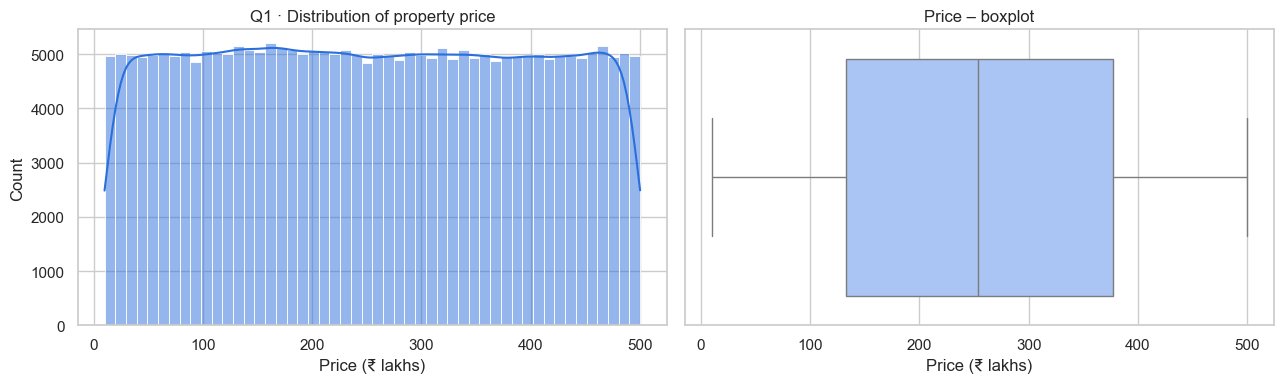

count   250,000.00
mean        254.60
std         141.30
min          10.00
25%         132.60
50%         253.90
75%         376.90
max         500.00


In [73]:
# Q1. Distribution of property prices
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Price_in_Lakhs"], bins=50, kde=True, ax=ax[0], color="#2a6fdb")
ax[0].set(title="Q1 · Distribution of property price", xlabel="Price (₹ lakhs)")
sns.boxplot(x=df["Price_in_Lakhs"], ax=ax[1], color="#9ec1ff")
ax[1].set(title="Price – boxplot", xlabel="Price (₹ lakhs)")
plt.tight_layout(); plt.show()
print(df["Price_in_Lakhs"].describe().round(1).to_string())

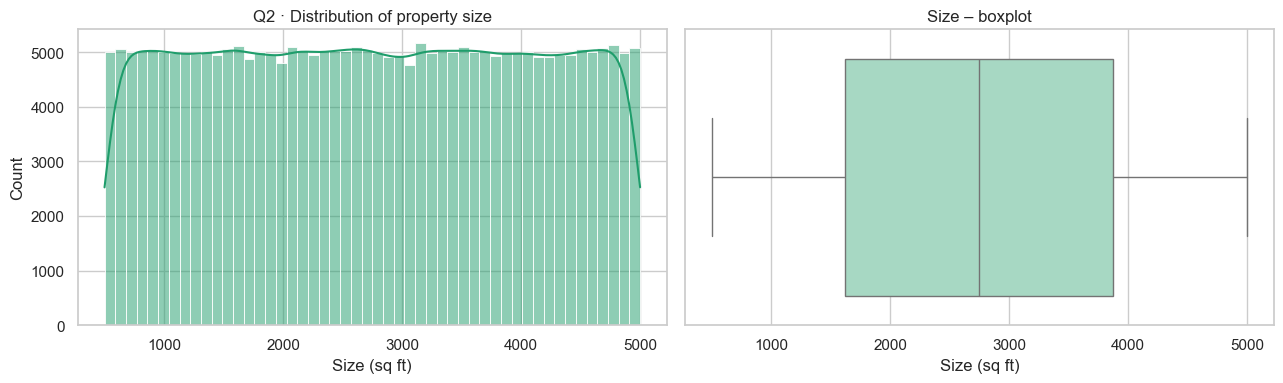

In [74]:
# Q2. Distribution of property sizes
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Size_in_SqFt"], bins=50, kde=True, ax=ax[0], color="#1f9d6b")
ax[0].set(title="Q2 · Distribution of property size", xlabel="Size (sq ft)")
sns.boxplot(x=df["Size_in_SqFt"], ax=ax[1], color="#9fe0c4")
ax[1].set(title="Size – boxplot", xlabel="Size (sq ft)")
plt.tight_layout(); plt.show()

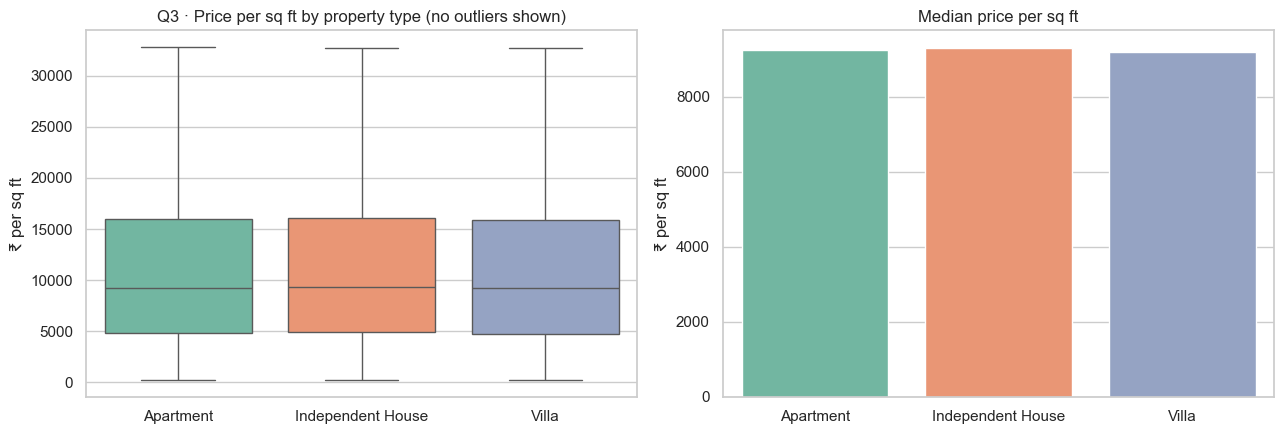

,mean,median
Property_Type,,
Apartment,"13,047.00","9,245.00"
Independent House,"13,102.00","9,305.00"
Villa,"13,026.00","9,190.00"


In [75]:
# Q3. Price per sq ft by property type
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_calc", ax=ax[0], showfliers=False, palette="Set2")
ax[0].set(title="Q3 · Price per sq ft by property type (no outliers shown)", ylabel="₹ per sq ft", xlabel="")
sns.barplot(data=df, x="Property_Type", y="Price_per_SqFt_calc", estimator=np.median, errorbar=None, ax=ax[1], palette="Set2")
ax[1].set(title="Median price per sq ft", ylabel="₹ per sq ft", xlabel="")
plt.tight_layout(); plt.show()
df.groupby("Property_Type")["Price_per_SqFt_calc"].agg(["mean", "median"]).round(0)

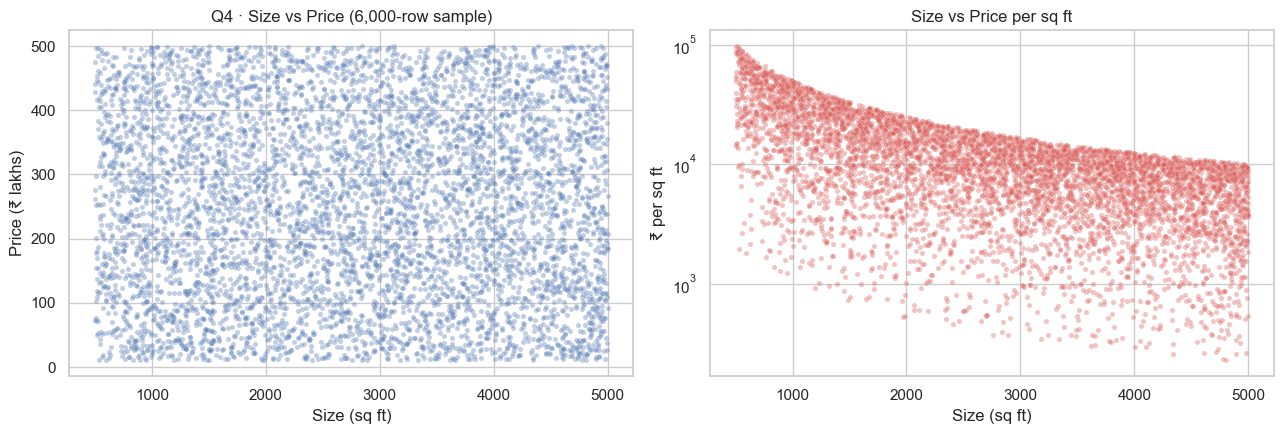

Pearson corr (size, price):          -0.003
Pearson corr (size, price per sqft): -0.615
Spearman corr (size, price per sqft): -0.599


In [76]:
# Q4. Relationship between size and price
s = df.sample(6000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=s, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.35, s=14, ax=ax[0])
ax[0].set(title="Q4 · Size vs Price (6,000-row sample)", xlabel="Size (sq ft)", ylabel="Price (₹ lakhs)")
sns.scatterplot(data=s, x="Size_in_SqFt", y="Price_per_SqFt_calc", alpha=0.35, s=14, ax=ax[1], color="#d9534f")
ax[1].set(title="Size vs Price per sq ft", xlabel="Size (sq ft)", ylabel="₹ per sq ft", yscale="log")
plt.tight_layout(); plt.show()
print("Pearson corr (size, price):          %.3f" % df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]))
print("Pearson corr (size, price per sqft): %.3f" % df["Size_in_SqFt"].corr(df["Price_per_SqFt_calc"]))
print("Spearman corr (size, price per sqft): %.3f" % df["Size_in_SqFt"].corr(df["Price_per_SqFt_calc"], method="spearman"))

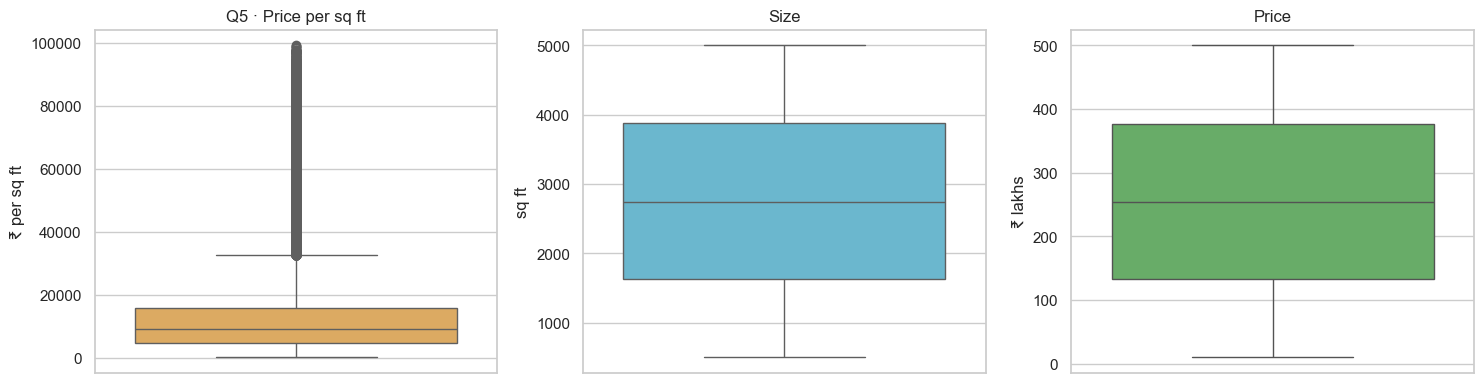

Price/sqft outliers (IQR rule): 19,723 rows (7.9%)
Size outliers: 0   |  Price outliers: 0  (both are bounded ranges)


In [77]:
# Q5. Outliers in price per sq ft and size
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["Price_per_SqFt_calc"], ax=ax[0], color="#f0ad4e"); ax[0].set(title="Q5 · Price per sq ft", ylabel="₹ per sq ft")
sns.boxplot(y=df["Size_in_SqFt"], ax=ax[1], color="#5bc0de");        ax[1].set(title="Size", ylabel="sq ft")
sns.boxplot(y=df["Price_in_Lakhs"], ax=ax[2], color="#5cb85c");      ax[2].set(title="Price", ylabel="₹ lakhs")
plt.tight_layout(); plt.show()
print(f"Price/sqft outliers (IQR rule): {df['PPSF_Outlier_Flag'].sum():,} rows ({df['PPSF_Outlier_Flag'].mean():.1%})")
print("Size outliers: 0   |  Price outliers: 0  (both are bounded ranges)")

**Takeaways (1–5)**
* Price (₹10–500 L) and size (500–5,000 sq ft) are both close to **uniformly distributed**, not right-skewed like real housing markets.
* Price per sq ft is strongly right-skewed – a *mechanical* effect of dividing a uniform price by a uniform size.
* **Size and total price are essentially uncorrelated (r ≈ 0)**, so bigger homes are *not* more expensive here – a strong sign the data is synthetic. Price per sq ft falls as size rises purely because of the division.
* Property types have almost identical price per sq ft.

### 6–10 · Location-based Analysis

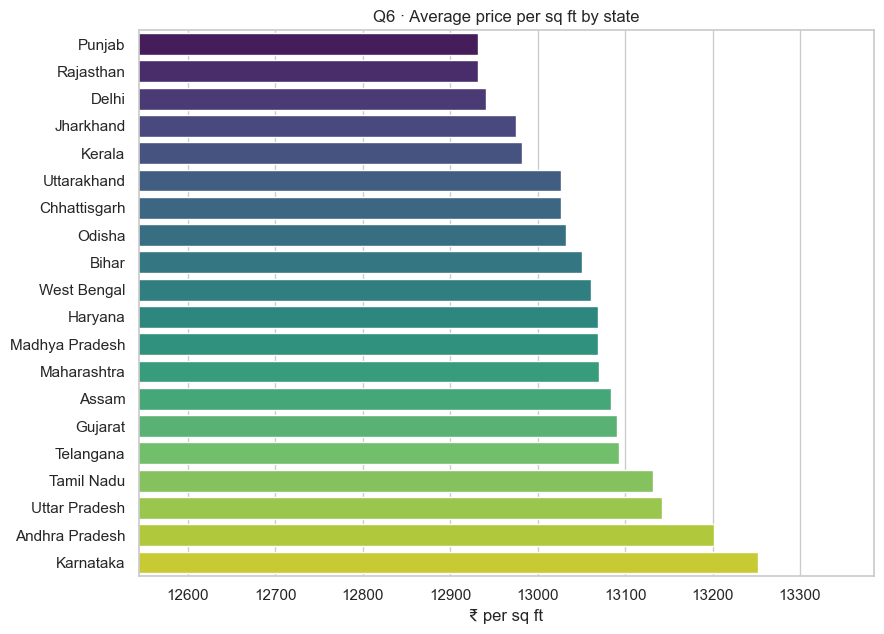

Spread between highest and lowest state: 2.5%


In [78]:
# Q6. Average price per sq ft by state
state_ppsf = df.groupby("State")["Price_per_SqFt_calc"].mean().sort_values()
plt.figure(figsize=(9, 6.5))
sns.barplot(x=state_ppsf.values, y=state_ppsf.index, palette="viridis")
plt.title("Q6 · Average price per sq ft by state"); plt.xlabel("₹ per sq ft"); plt.ylabel("")
plt.xlim(state_ppsf.min() * 0.97, state_ppsf.max() * 1.01)
plt.tight_layout(); plt.show()
print("Spread between highest and lowest state: %.1f%%" % ((state_ppsf.max() / state_ppsf.min() - 1) * 100))

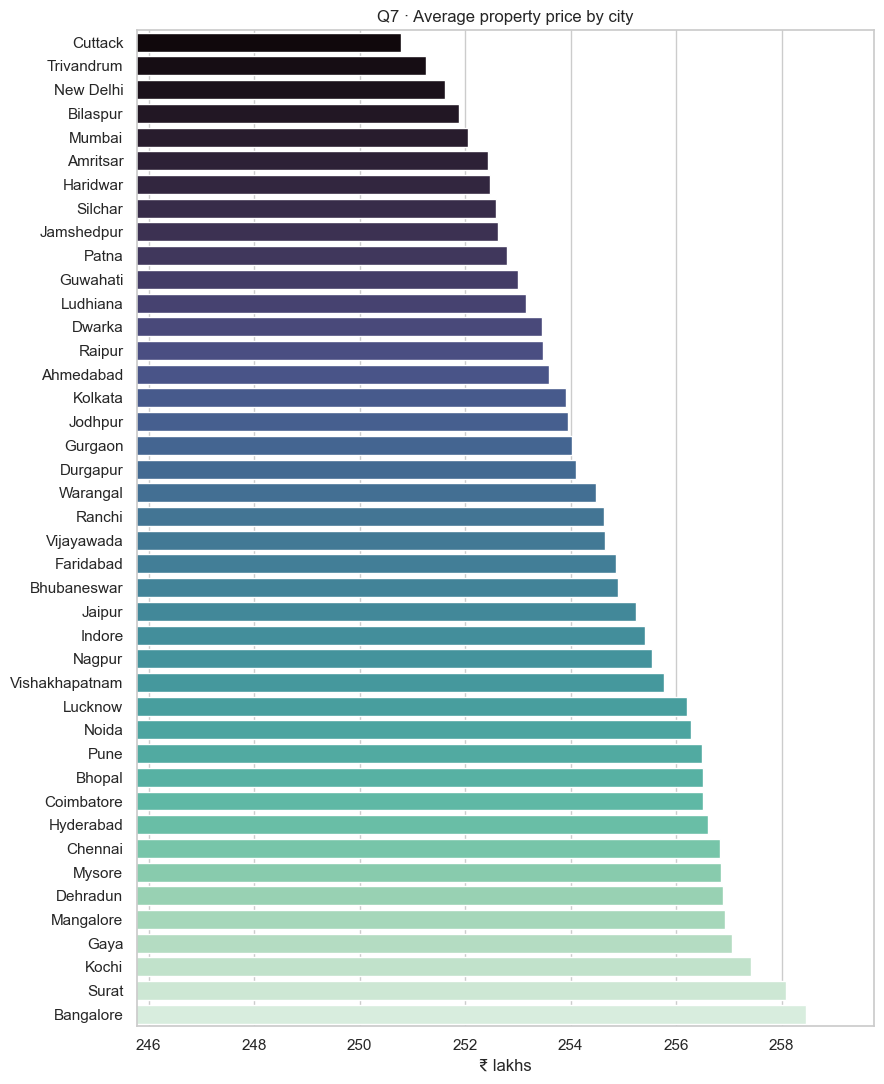

Top 3 cities: Bangalore, Surat, Kochi
Spread between highest and lowest city: 3.1%


In [79]:
# Q7. Average property price by city
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()
plt.figure(figsize=(9, 11))
sns.barplot(x=city_price.values, y=city_price.index, palette="mako")
plt.title("Q7 · Average property price by city"); plt.xlabel("₹ lakhs"); plt.ylabel("")
plt.xlim(city_price.min() * 0.98, city_price.max() * 1.005)
plt.tight_layout(); plt.show()
print("Top 3 cities:", ", ".join(city_price.index[-3:][::-1]))
print("Spread between highest and lowest city: %.1f%%" % ((city_price.max() / city_price.min() - 1) * 100))

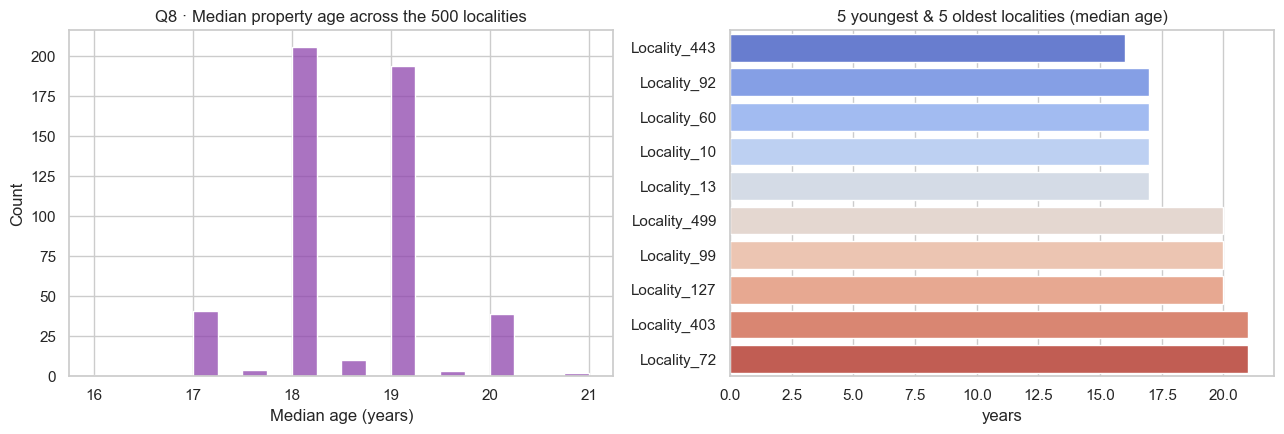

count   500.00
mean     18.50
std       0.80
min      16.00
25%      18.00
50%      18.00
75%      19.00
max      21.00


In [80]:
# Q8. Median age of properties by locality
loc_age = df.groupby("Locality")["Age_of_Property"].median()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(loc_age, bins=20, ax=ax[0], color="#8e44ad")
ax[0].set(title="Q8 · Median property age across the 500 localities", xlabel="Median age (years)")
extremes = pd.concat([loc_age.sort_values().head(5), loc_age.sort_values().tail(5)])
sns.barplot(x=extremes.values, y=extremes.index, ax=ax[1], palette="coolwarm")
ax[1].set(title="5 youngest & 5 oldest localities (median age)", xlabel="years", ylabel="")
plt.tight_layout(); plt.show()
print(loc_age.describe().round(1).to_string())

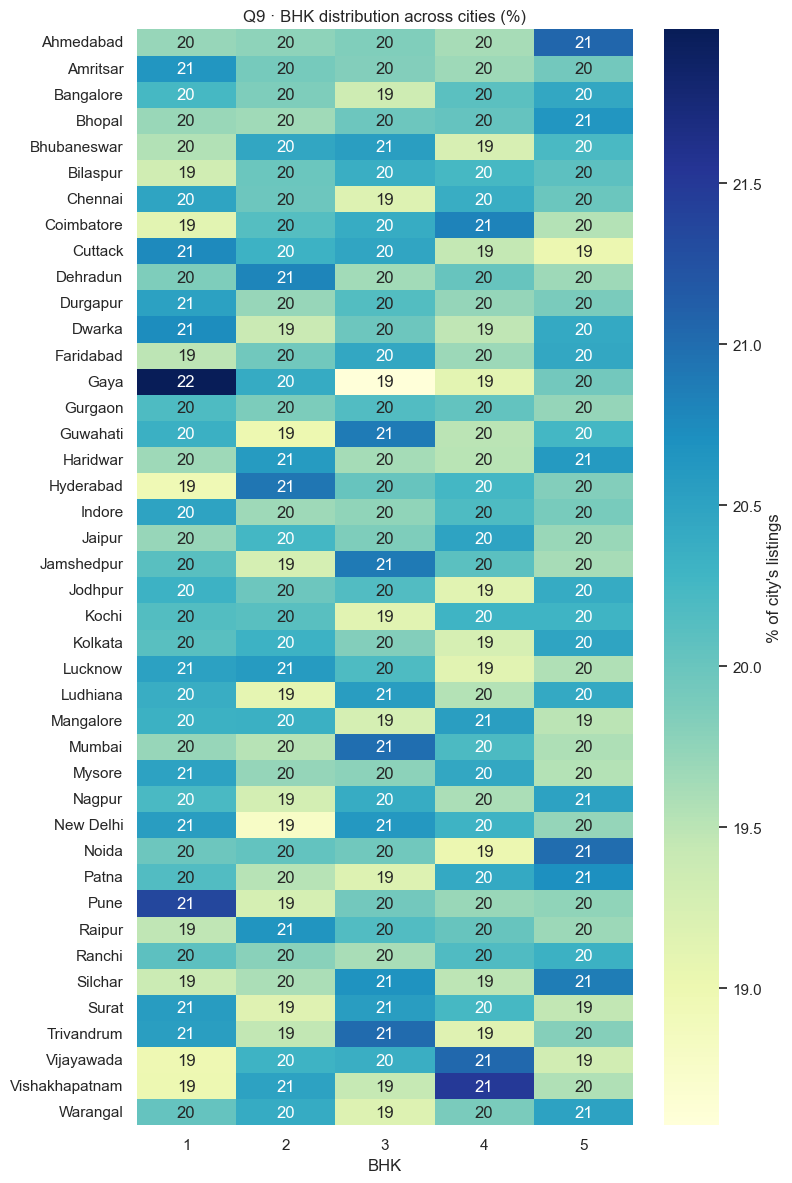

In [81]:
# Q9. BHK distribution across cities
bhk_city = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100
plt.figure(figsize=(8, 12))
sns.heatmap(bhk_city, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "% of city's listings"})
plt.title("Q9 · BHK distribution across cities (%)"); plt.ylabel(""); plt.tight_layout(); plt.show()

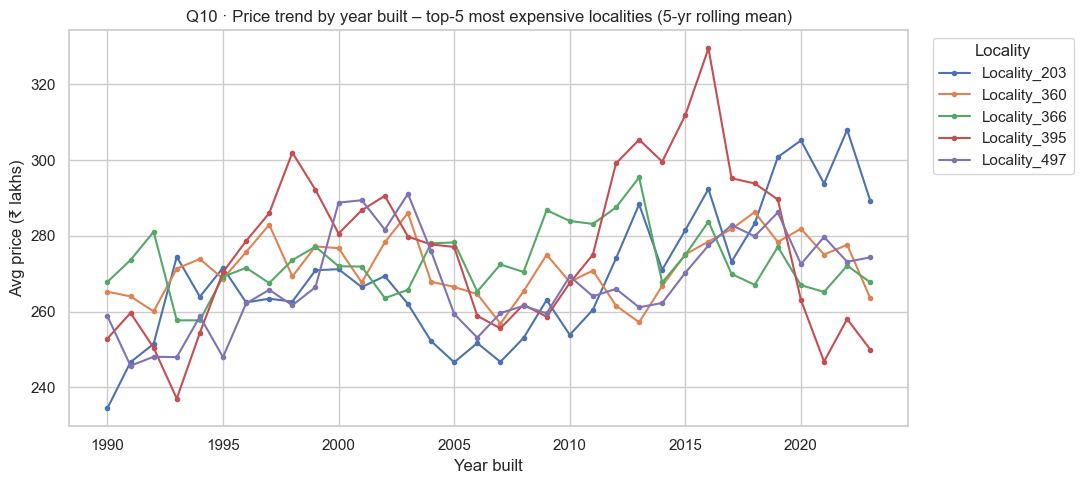

Top-5 localities: ['Locality_395', 'Locality_366', 'Locality_497', 'Locality_360', 'Locality_203']


In [82]:
# Q10. Price trend for the top-5 most expensive localities (by average price)
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index.tolist()
trend = (df[df["Locality"].isin(top5)].groupby(["Year_Built", "Locality"])["Price_in_Lakhs"].mean()
           .unstack("Locality").rolling(5, min_periods=1, center=True).mean())      # 5-year rolling mean
ax = trend.plot(figsize=(11, 5), marker="o", ms=3)
ax.set(title="Q10 · Price trend by year built – top-5 most expensive localities (5-yr rolling mean)",
       xlabel="Year built", ylabel="Avg price (₹ lakhs)")
plt.legend(title="Locality", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()
print("Top-5 localities:", top5)

**Takeaways (6–10)**
* State and city averages differ by only a **few percent** (all cities sit around ₹250–258 L). Location is *not* a strong price driver in this dataset.
* Locality names (`Locality_1 … Locality_500`) are **reused in every city** (each appears in ~42 cities), so a "locality" here is a pooled label rather than a real neighbourhood.
* Median property age is ~18 years nearly everywhere, and BHK mix is similar in all cities.
* The "top-5 locality trend" lines are noisy with no consistent upward trend – there is no real time signal in `Year_Built`.

### 11–15 · Feature Relationships & Correlation

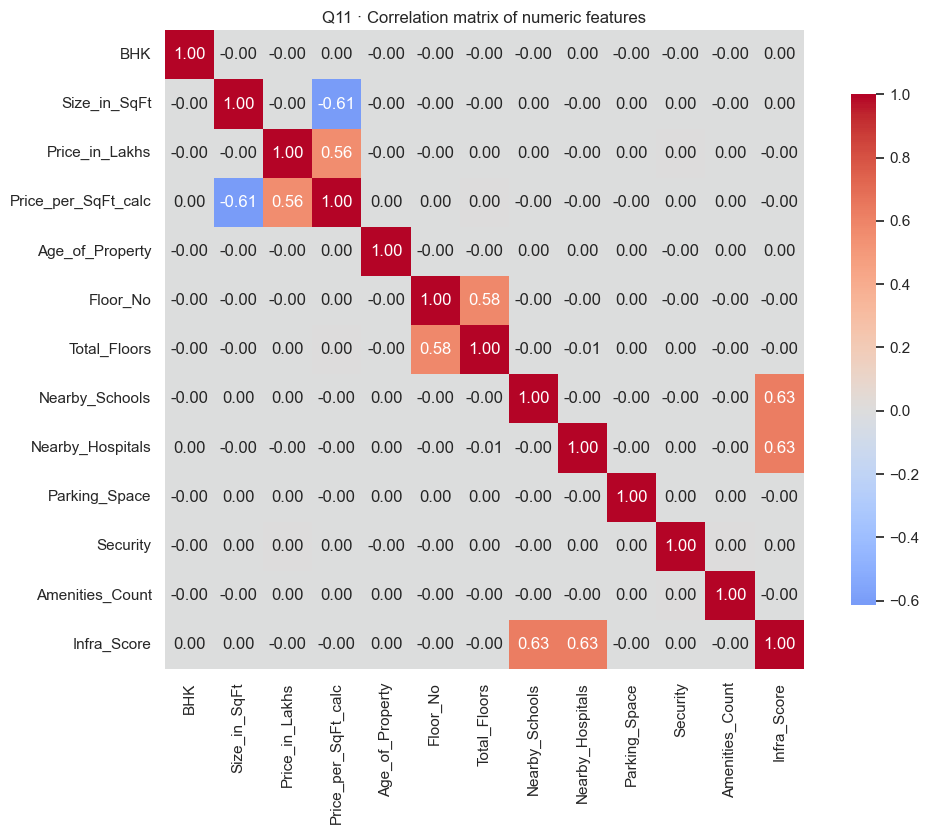

In [83]:
# Q11. Correlation among numeric features
corr_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_calc", "Age_of_Property", "Floor_No", "Total_Floors",
             "Nearby_Schools", "Nearby_Hospitals", "Parking_Space", "Security", "Amenities_Count", "Infra_Score"]
plt.figure(figsize=(11, 8.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Q11 · Correlation matrix of numeric features"); plt.tight_layout(); plt.show()

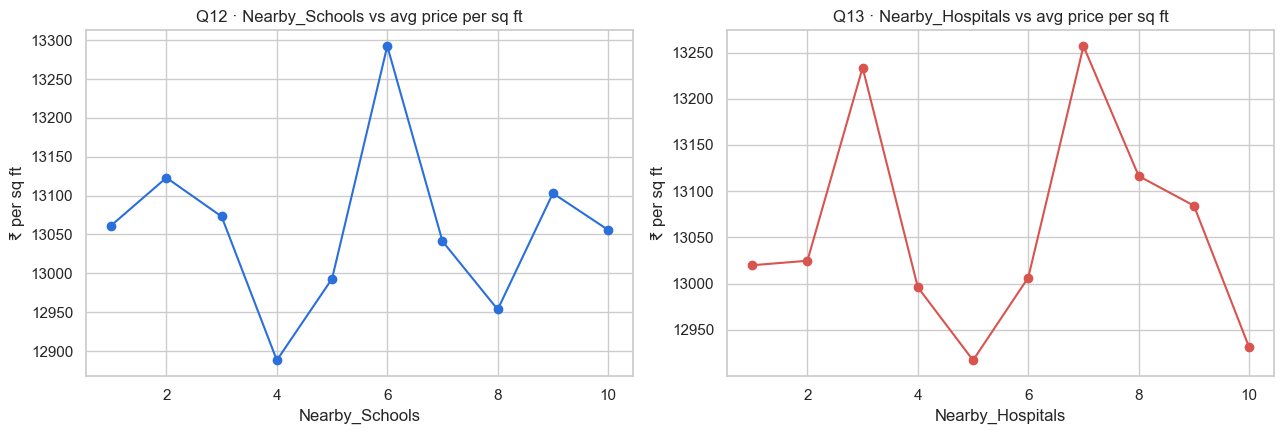

corr(schools, ppsf)   = -0.000
corr(hospitals, ppsf) = -0.000


In [84]:
# Q12 & Q13. Schools / hospitals vs price per sq ft
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, c in zip(ax, ["Nearby_Schools", "Nearby_Hospitals"], ["#2a6fdb", "#d9534f"]):
    g = df.groupby(col)["Price_per_SqFt_calc"].mean()
    a.plot(g.index, g.values, marker="o", color=c)
    a.set(title=f"{'Q12' if 'School' in col else 'Q13'} · {col} vs avg price per sq ft",
          xlabel=col, ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()
print("corr(schools, ppsf)   = %.3f" % df["Nearby_Schools"].corr(df["Price_per_SqFt_calc"]))
print("corr(hospitals, ppsf) = %.3f" % df["Nearby_Hospitals"].corr(df["Price_per_SqFt_calc"]))

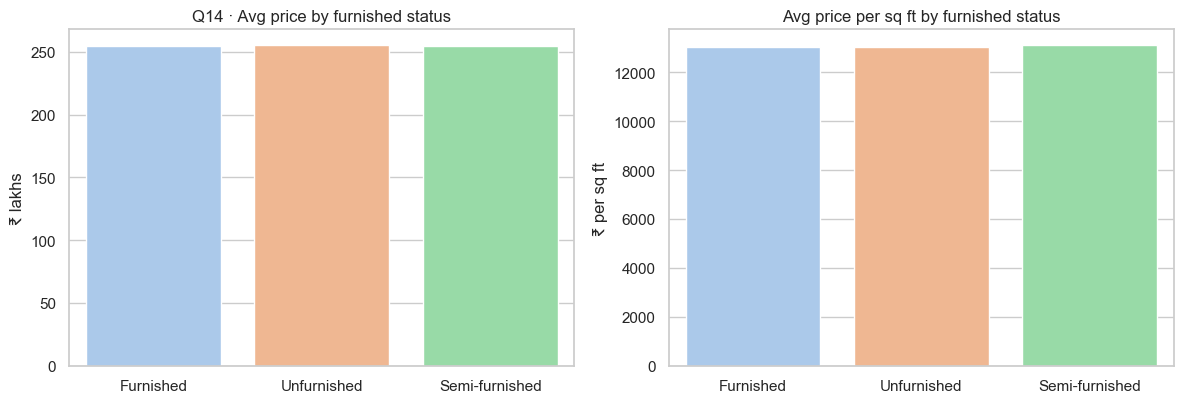

In [85]:
# Q14. Price by furnished status
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", errorbar=None, ax=ax[0], palette="pastel")
ax[0].set(title="Q14 · Avg price by furnished status", ylabel="₹ lakhs", xlabel="")
sns.barplot(data=df, x="Furnished_Status", y="Price_per_SqFt_calc", errorbar=None, ax=ax[1], palette="pastel")
ax[1].set(title="Avg price per sq ft by furnished status", ylabel="₹ per sq ft", xlabel="")
plt.tight_layout(); plt.show()

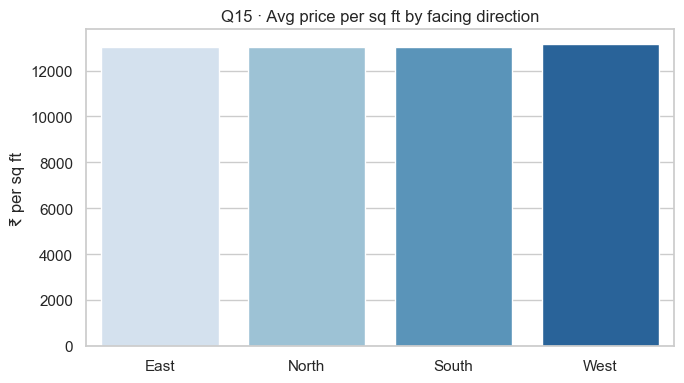

In [86]:
# Q15. Price per sq ft by facing direction
order = df.groupby("Facing")["Price_per_SqFt_calc"].mean().sort_values().index
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Facing", y="Price_per_SqFt_calc", order=order, errorbar=None, palette="Blues")
plt.title("Q15 · Avg price per sq ft by facing direction"); plt.ylabel("₹ per sq ft"); plt.xlabel("")
plt.tight_layout(); plt.show()

**Takeaways (11–15)**
* The only notable correlations are the **mechanical** ones: `Price_per_SqFt_calc` with price (+) and with size (−).
  All other pairs are ≈ 0, including schools/hospitals vs price per sq ft.
* Furnished status and facing direction move price by **< 1–2 %** – statistically tiny.

### 16–20 · Investment, Amenities & Ownership Analysis

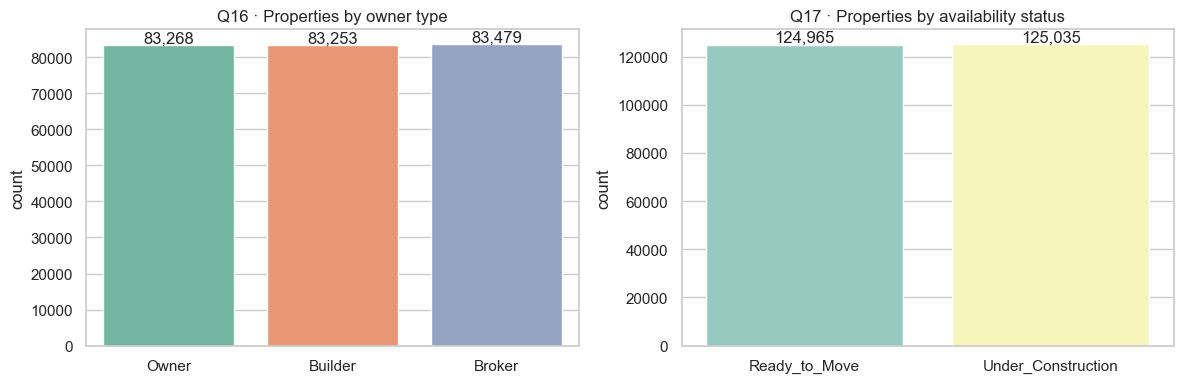

In [87]:
# Q16 & Q17. Owner type and availability status
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Owner_Type", ax=ax[0], palette="Set2"); ax[0].set(title="Q16 · Properties by owner type", xlabel="")
sns.countplot(data=df, x="Availability_Status", ax=ax[1], palette="Set3"); ax[1].set(title="Q17 · Properties by availability status", xlabel="")
for a in ax:
    for p in a.patches:
        a.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

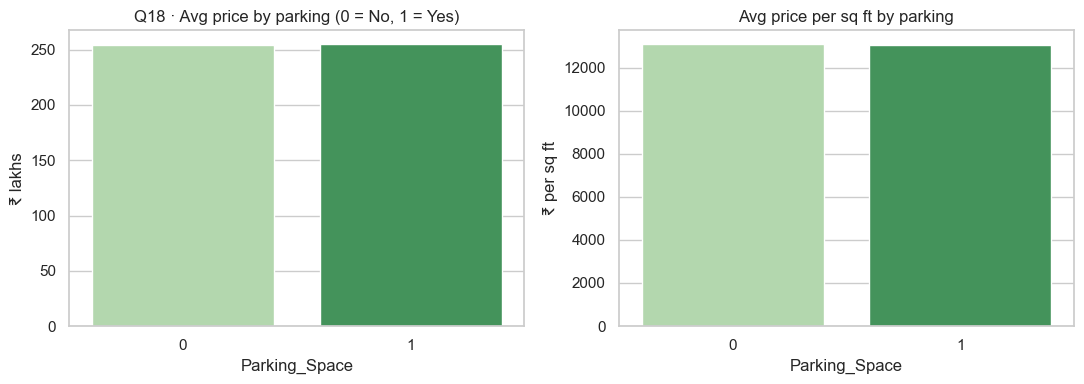

Price premium with parking: 0.12%


In [88]:
# Q18. Does parking affect price?
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="Parking_Space", y="Price_in_Lakhs", errorbar=None, ax=ax[0], palette="Greens")
ax[0].set(title="Q18 · Avg price by parking (0 = No, 1 = Yes)", ylabel="₹ lakhs")
sns.barplot(data=df, x="Parking_Space", y="Price_per_SqFt_calc", errorbar=None, ax=ax[1], palette="Greens")
ax[1].set(title="Avg price per sq ft by parking", ylabel="₹ per sq ft")
plt.tight_layout(); plt.show()
g = df.groupby("Parking_Space")["Price_in_Lakhs"].mean()
print("Price premium with parking: %.2f%%" % ((g[1] / g[0] - 1) * 100))

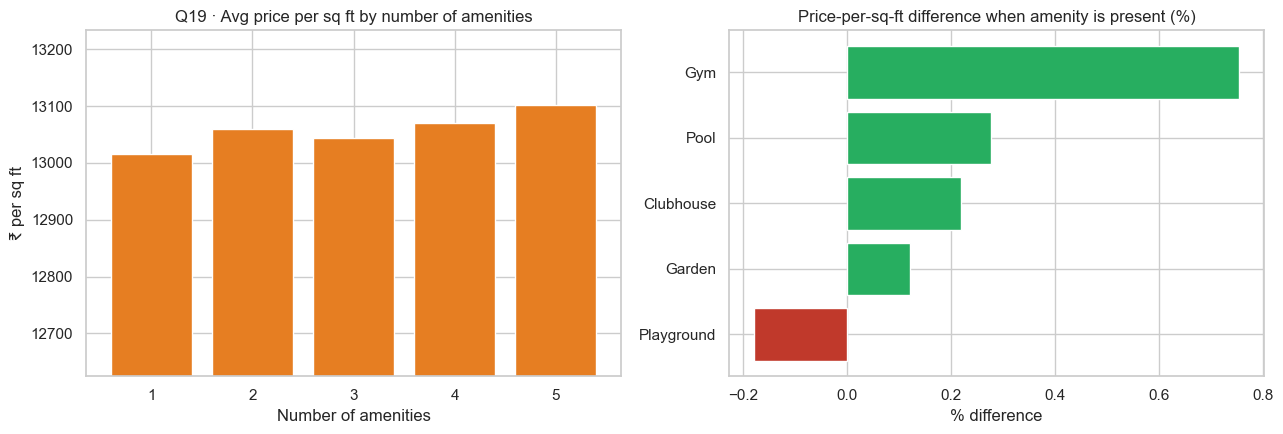

In [89]:
# Q19. Amenities vs price per sq ft
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
g = df.groupby("Amenities_Count")["Price_per_SqFt_calc"].mean()
ax[0].bar(g.index.astype(str), g.values, color="#e67e22")
ax[0].set(title="Q19 · Avg price per sq ft by number of amenities", xlabel="Number of amenities", ylabel="₹ per sq ft")
ax[0].set_ylim(g.min() * 0.97, g.max() * 1.01)

effect = {a: df.loc[df[f"Has_{a}"] == 1, "Price_per_SqFt_calc"].mean() / df.loc[df[f"Has_{a}"] == 0, "Price_per_SqFt_calc"].mean() - 1
          for a in ["Gym", "Pool", "Clubhouse", "Playground", "Garden"]}
effect = pd.Series(effect).mul(100).sort_values()
ax[1].barh(effect.index, effect.values, color=np.where(effect.values >= 0, "#27ae60", "#c0392b"))
ax[1].set(title="Price-per-sq-ft difference when amenity is present (%)", xlabel="% difference")
plt.tight_layout(); plt.show()

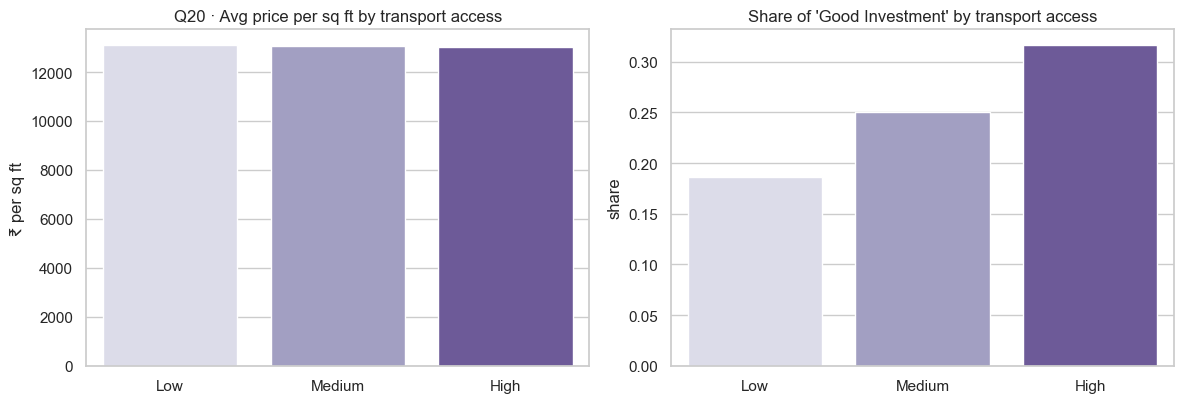

In [90]:
# Q20. Public transport accessibility vs price per sq ft and investment potential
order = ["Low", "Medium", "High"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Price_per_SqFt_calc", order=order, errorbar=None, ax=ax[0], palette="Purples")
ax[0].set(title="Q20 · Avg price per sq ft by transport access", ylabel="₹ per sq ft", xlabel="")
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Good_Investment", order=order, errorbar=None, ax=ax[1], palette="Purples")
ax[1].set(title="Share of 'Good Investment' by transport access", ylabel="share", xlabel="")
plt.tight_layout(); plt.show()

**Takeaways (16–20)**
* Owner types (Broker / Owner / Builder) and availability (Ready to Move / Under Construction) are split almost exactly **⅓ : ⅓ : ⅓** and **50 : 50**.
* Parking, amenity count, individual amenities and transport access change price by only a **fraction of a percent**.
* Transport access **does** matter for the *engineered* investment label (better access → higher share of Good Investments) because we put it in the appreciation rule – this is by design, not an empirical finding.

### Extra analyses from the brief (Approach → Step 2)

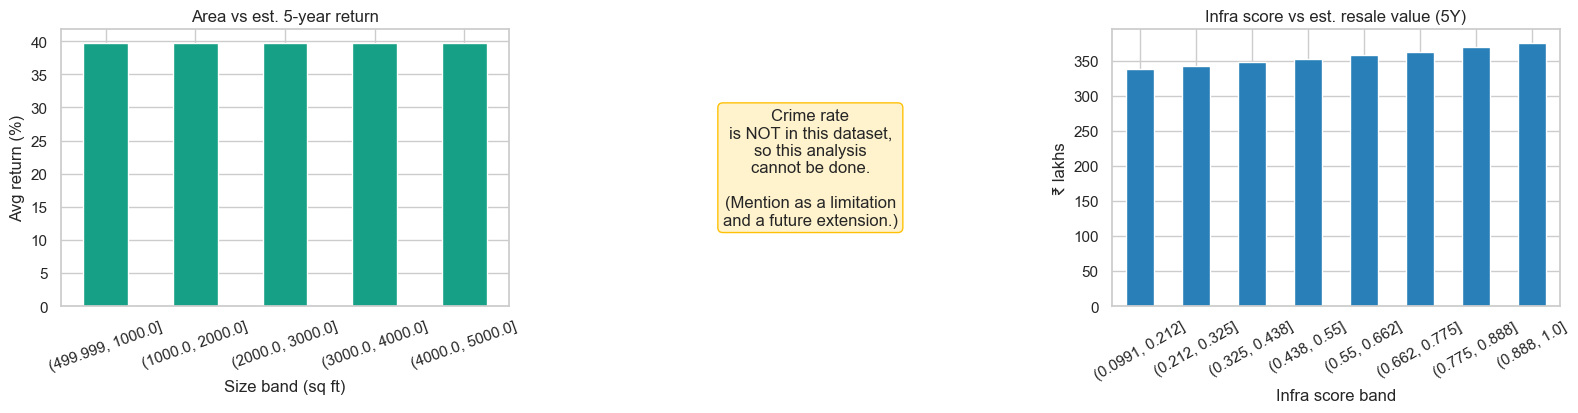

corr(size, 5Y return)       = 0.002
corr(infra score, 5Y price) = 0.043


In [91]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))

# (a) Area vs investment return (estimated 5-year return)
df["Return_5Y_Pct"] = (df["Future_Price_5Y"] / df["Price_in_Lakhs"] - 1) * 100
bins = pd.cut(df["Size_in_SqFt"], bins=[500, 1000, 2000, 3000, 4000, 5000], include_lowest=True)
df.groupby(bins, observed=True)["Return_5Y_Pct"].mean().plot(kind="bar", ax=ax[0], color="#16a085", rot=20)
ax[0].set(title="Area vs est. 5-year return", xlabel="Size band (sq ft)", ylabel="Avg return (%)")

# (b) Crime rate vs Good Investment -> not available
ax[1].axis("off")
ax[1].text(0.5, 0.5, "Crime rate\nis NOT in this dataset,\nso this analysis\ncannot be done.\n\n(Mention as a limitation\nand a future extension.)",
           ha="center", va="center", fontsize=12, bbox=dict(boxstyle="round", fc="#fff3cd", ec="#ffc107"))

# (c) Infrastructure score vs resale value
df.groupby(pd.cut(df["Infra_Score"], 8), observed=True)["Future_Price_5Y"].mean().plot(kind="bar", ax=ax[2], color="#2980b9", rot=30)
ax[2].set(title="Infra score vs est. resale value (5Y)", xlabel="Infra score band", ylabel="₹ lakhs")
plt.tight_layout(); plt.show()
print("corr(size, 5Y return)       = %.3f" % df["Size_in_SqFt"].corr(df["Return_5Y_Pct"]))
print("corr(infra score, 5Y price) = %.3f" % df["Infra_Score"].corr(df["Future_Price_5Y"]))

In [92]:
# Which properties are 'Good Investments'? Compare the two groups
cmp = df.groupby("Good_Investment")[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_calc", "Age_of_Property",
                                     "Infra_Score", "Est_Annual_Growth_Pct", "Return_5Y_Pct"]].mean().T
cmp.columns = ["Not good (0)", "Good (1)"]
cmp

,Not good (0),Good (1)
Price_in_Lakhs,285.64,162.00
Size_in_SqFt,"2,536.05","3,387.14"
Price_per_SqFt_calc,"15,822.10","4,817.88"
Age_of_Property,19.61,15.11
Infra_Score,0.52,0.63
Est_Annual_Growth_Pct,6.67,7.64
Return_5Y_Pct,38.17,44.54


### 🔑 Overall EDA conclusion
Almost every feature is **statistically independent** of price – cities, states, amenities, furnishing and facing change prices by only ~1–3 %.
The strongest patterns are mechanical (price per sq ft vs size). This strongly suggests the dataset is **synthetically generated**.
The documentation should say this openly: the models are a valid *engineering* pipeline, but their predictions should not be treated as real market advice.

## Part 6 · Model Preparation
Features exclude everything used to *define* the targets directly (`Price_vs_City_Median`, `Est_Annual_Growth_Pct`, `Infra_Score`, the label itself, and `Future_Price_5Y`)
so the models must learn from raw property attributes rather than being handed the answer.

In [93]:
CAT_FEATURES = ["City", "Property_Type", "Furnished_Status", "Public_Transport_Accessibility",
                "Facing", "Owner_Type", "Availability_Status"]
NUM_FEATURES = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_calc", "Floor_No", "Total_Floors",
                "Floor_Ratio", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals", "Parking_Space",
                "Security", "Amenities_Count", "Size_per_BHK"]
FEATURES = CAT_FEATURES + NUM_FEATURES

X = df[FEATURES]
y_clf = df["Good_Investment"]
y_reg = df["Future_Price_5Y"]

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Good-investment share – train: %.1f%%, test: %.1f%%" % (yc_train.mean() * 100, yc_test.mean() * 100))

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),                                          # feature scaling
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES) # categorical encoding
    ])

Train: (200000, 21)  Test: (50000, 21)
Good-investment share – train: 25.1%, test: 25.1%


In [94]:
# ---- MLflow helper (skips silently if MLflow is not installed) ----
if HAS_MLFLOW:
    mlflow.set_tracking_uri("sqlite:///mlflow.db")      # view with:  mlflow ui --backend-store-uri sqlite:///mlflow.db

def log_to_mlflow(experiment, run_name, pipe, metrics, extra_params=None):
    if not HAS_MLFLOW:
        return
    mlflow.set_experiment(experiment)
    est = pipe.named_steps["model"]
    params = {k: v for k, v in est.get_params().items() if isinstance(v, (int, float, str, bool, type(None)))}
    params.update(extra_params or {})
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(pipe, "model")

## Part 7 · Classification – *Is this a Good Investment?*

In [95]:
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=60, max_depth=12, min_samples_leaf=10, max_samples=0.3, max_features="sqrt", n_jobs=-1,
                                            class_weight="balanced_subsample", random_state=RANDOM_STATE),
}
if HAS_XGB:
    clf_models["XGBoost"] = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                                              colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE,
                                              eval_metric="logloss")
else:
    clf_models["Hist Gradient Boosting"] = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                                                          random_state=RANDOM_STATE)

clf_results, clf_pipes = [], {}
for name, est in clf_models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("model", est)]).fit(X_train, yc_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    m = {"accuracy": accuracy_score(yc_test, pred), "precision": precision_score(yc_test, pred),
         "recall": recall_score(yc_test, pred), "f1": f1_score(yc_test, pred), "roc_auc": roc_auc_score(yc_test, proba)}
    clf_results.append({"model": name, **m, "train_sec": time.time() - t0})
    clf_pipes[name] = pipe
    log_to_mlflow("Real_Estate_Classification", name, pipe, m, {"task": "good_investment"})
    print(f"{name:<24} acc={m['accuracy']:.4f}  f1={m['f1']:.4f}  auc={m['roc_auc']:.4f}  ({time.time()-t0:.0f}s)")

clf_df = pd.DataFrame(clf_results).set_index("model").sort_values("f1", ascending=False)
clf_df

Logistic Regression      acc=0.8955  f1=0.8157  auc=0.9674  (3s)
Random Forest            acc=0.9256  f1=0.8690  auc=0.9881  (10s)
Hist Gradient Boosting   acc=0.9947  f1=0.9894  auc=0.9998  (54s)


,accuracy,precision,recall,f1,roc_auc,train_sec
model,,,,,,
Hist Gradient Boosting,0.99,0.99,0.99,0.99,1.00,53.64
Random Forest,0.93,0.78,0.98,0.87,0.99,10.40
Logistic Regression,0.90,0.73,0.92,0.82,0.97,3.30


Best classifier: Hist Gradient Boosting


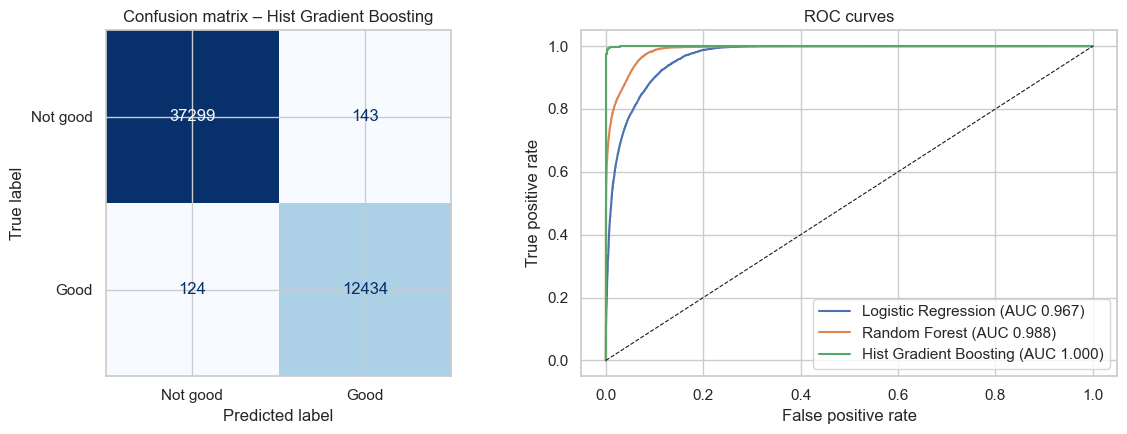

Average prediction confidence on test set: 97.8%


In [96]:
best_clf_name = clf_df.index[0]
best_clf = clf_pipes[best_clf_name]
proba = best_clf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print("Best classifier:", best_clf_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(yc_test, pred), display_labels=["Not good", "Good"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix – {best_clf_name}")
for name, p in clf_pipes.items():
    fpr, tpr, _ = roc_curve(yc_test, p.predict_proba(X_test)[:, 1])
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yc_test, p.predict_proba(X_test)[:, 1]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate"); ax[1].legend()
plt.tight_layout(); plt.show()

# Model confidence = predicted probability (shown in the Streamlit app)
conf = np.maximum(proba, 1 - proba)
print("Average prediction confidence on test set: %.1f%%" % (conf.mean() * 100))

> **How to read these scores.** The label was created from rules on price, city, size and infrastructure, so a strong model can recover it almost perfectly.
> High accuracy here demonstrates that the pipeline works, **not** that the model can forecast real-world investment outcomes. Compare the baseline (always predict "not good" ≈ 75 % accuracy) when presenting results.

## Part 8 · Regression – *Estimated price after 5 years*

In [97]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=10, max_samples=0.3, max_features=0.5,
                                           n_jobs=-1, random_state=RANDOM_STATE),
}
if HAS_XGB:
    reg_models["XGBoost"] = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8,
                                             colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)
else:
    reg_models["Hist Gradient Boosting"] = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.1,
                                                                         random_state=RANDOM_STATE)

# baseline: simply assume the same growth for everyone (mean growth) – any useful model must beat this
base_g = df.loc[X_train.index, "Est_Annual_Growth_Pct"].mean()
baseline_pred = X_test["Price_in_Lakhs"] * (1 + base_g / 100) ** YEARS
reg_results = [{"model": "Baseline (flat growth)",
                "rmse": np.sqrt(mean_squared_error(yr_test, baseline_pred)),
                "mae": mean_absolute_error(yr_test, baseline_pred), "r2": r2_score(yr_test, baseline_pred), "train_sec": 0}]
reg_pipes = {}
for name, est in reg_models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", make_preprocessor()), ("model", est)]).fit(X_train, yr_train)
    pred = pipe.predict(X_test)
    m = {"rmse": np.sqrt(mean_squared_error(yr_test, pred)), "mae": mean_absolute_error(yr_test, pred), "r2": r2_score(yr_test, pred)}
    reg_results.append({"model": name, **m, "train_sec": time.time() - t0})
    reg_pipes[name] = pipe
    log_to_mlflow("Real_Estate_Regression", name, pipe, m, {"task": "future_price_5y"})
    print(f"{name:<24} RMSE={m['rmse']:.2f}  MAE={m['mae']:.2f}  R2={m['r2']:.4f}  ({time.time()-t0:.0f}s)")

reg_df = pd.DataFrame(reg_results).set_index("model")
reg_df.sort_values("rmse")

Linear Regression        RMSE=8.28  MAE=5.81  R2=0.9983  (4s)
Random Forest            RMSE=7.10  MAE=5.26  R2=0.9987  (21s)
Hist Gradient Boosting   RMSE=1.33  MAE=1.05  R2=1.0000  (42s)


,rmse,mae,r2,train_sec
model,,,,
Hist Gradient Boosting,1.33,1.05,1.00,42.41
Random Forest,7.10,5.26,1.00,21.45
Linear Regression,8.28,5.81,1.00,4.03
Baseline (flat growth),17.06,12.08,0.99,0.00


Best regressor: Hist Gradient Boosting


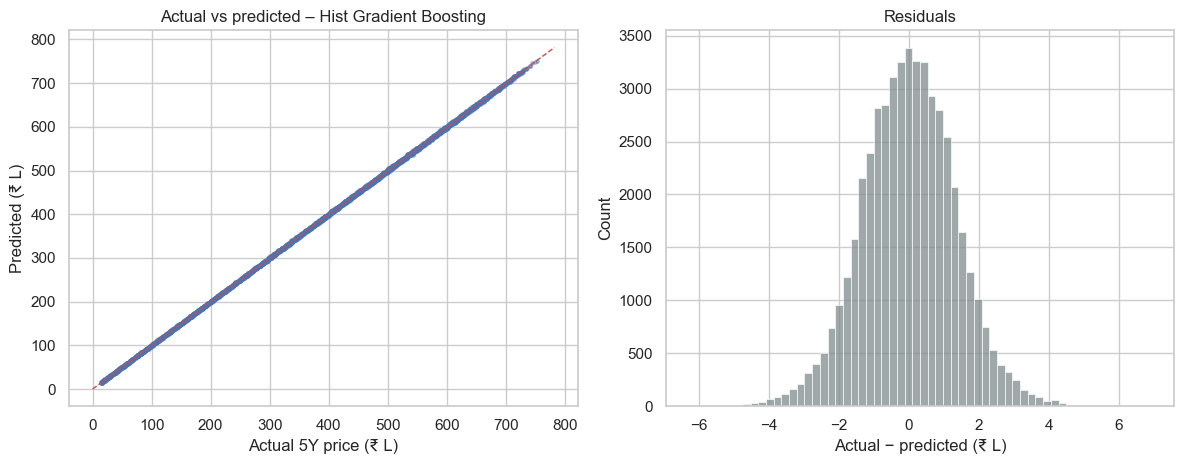

In [98]:
best_reg_name = reg_df.drop(index="Baseline (flat growth)")["rmse"].idxmin()
best_reg = reg_pipes[best_reg_name]
pred = best_reg.predict(X_test)
print("Best regressor:", best_reg_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
idx = np.random.RandomState(0).choice(len(pred), 4000, replace=False)
ax[0].scatter(np.asarray(yr_test)[idx], pred[idx], s=6, alpha=0.4)
lim = [0, max(yr_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--", lw=1); ax[0].set(title=f"Actual vs predicted – {best_reg_name}", xlabel="Actual 5Y price (₹ L)", ylabel="Predicted (₹ L)")
resid = np.asarray(yr_test) - pred
sns.histplot(resid, bins=60, ax=ax[1], color="#7f8c8d"); ax[1].set(title="Residuals", xlabel="Actual − predicted (₹ L)")
plt.tight_layout(); plt.show()

> **How to read these scores.** Future price is mostly today's price × ~1.4, so even the flat-growth baseline gets a very high R². The meaningful comparison is the **RMSE / MAE versus that baseline**:
> the gradient-boosting model cuts the error by a large factor because it learns the property-specific growth rule. Again, this shows the pipeline works on the *assumed* growth model, not on real market data.

## Part 9 · Feature Importance & Saving Artifacts

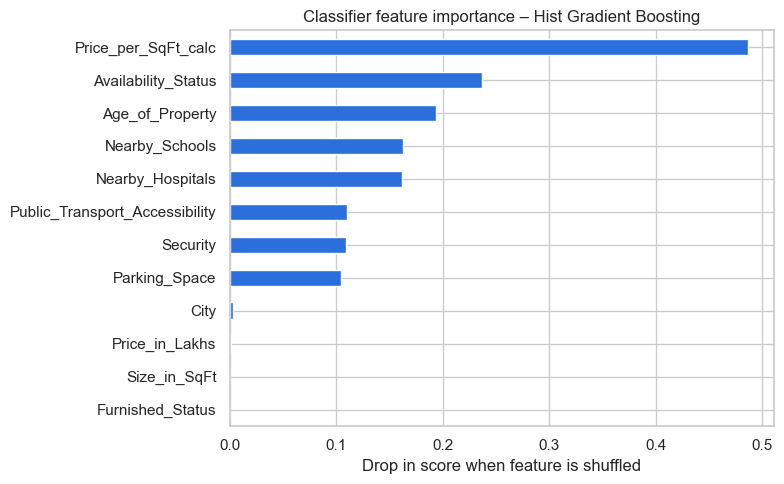

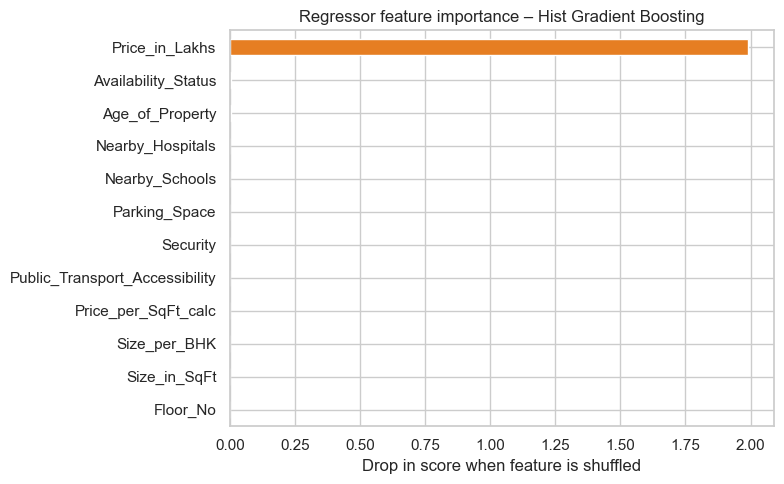

In [61]:
# Permutation importance works for every model type and reports original (un-encoded) features
def plot_perm_importance(pipe, X_, y_, scoring, title, color):
    sub = X_.sample(8000, random_state=RANDOM_STATE)
    r = permutation_importance(pipe, sub, y_.loc[sub.index], n_repeats=3, random_state=RANDOM_STATE, scoring=scoring, n_jobs=1)
    imp = pd.Series(r.importances_mean, index=X_.columns).sort_values()
    imp.tail(12).plot(kind="barh", figsize=(8, 5), color=color)
    plt.title(title); plt.xlabel("Drop in score when feature is shuffled"); plt.tight_layout(); plt.show()
    return imp.sort_values(ascending=False)

clf_imp = plot_perm_importance(best_clf, X_test, yc_test, "f1", f"Classifier feature importance – {best_clf_name}", "#2a6fdb")
reg_imp = plot_perm_importance(best_reg, X_test, yr_test, "r2", f"Regressor feature importance – {best_reg_name}", "#e67e22")

In [62]:
# Save everything the Streamlit app will need
joblib.dump(best_clf, "models/best_classifier.joblib")
joblib.dump(best_reg, "models/best_regressor.joblib")

metadata = {
    "features": FEATURES, "cat_features": CAT_FEATURES, "num_features": NUM_FEATURES,
    "city_median_ppsf": city_median_ppsf.round(2).to_dict(),
    "city_to_state": df.drop_duplicates("City").set_index("City")["State"].to_dict(),
    "categories": {c: sorted(df[c].unique().tolist()) for c in CAT_FEATURES},
    "growth_threshold": float(GROWTH_THRESHOLD),
    "assumptions": {"base_growth": BASE_GROWTH, "w_infra": W_INFRA, "w_under_construction": W_UNDER_CONSTRUCTION,
                    "w_security": W_SECURITY, "w_parking": W_PARKING, "w_age": W_AGE, "years": YEARS},
    "best_classifier": best_clf_name, "best_regressor": best_reg_name,
    "classifier_metrics": clf_df.loc[best_clf_name].to_dict(),
    "regressor_metrics": reg_df.loc[best_reg_name].to_dict(),
    "classifier_importance": clf_imp.head(10).to_dict(), "regressor_importance": reg_imp.head(10).to_dict(),
}
with open("models/app_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=float)
clf_df.to_csv(os.path.join(OUT_DIR, "classification_results.csv"))
reg_df.to_csv(os.path.join(OUT_DIR, "regression_results.csv"))
print("Saved: models/best_classifier.joblib, models/best_regressor.joblib, models/app_metadata.json, results CSVs")

Saved: models/best_classifier.joblib, models/best_regressor.joblib, models/app_metadata.json, results CSVs


In [63]:
# Quick sanity check: predict for one sample property, exactly as the app will
sample = X_test.iloc[[0]]
p = best_clf.predict_proba(sample)[0, 1]
print(sample.T.head(8).to_string(), "\n")
print(f"Good Investment?       {'YES' if p >= 0.5 else 'NO'}  (confidence {max(p, 1 - p):.1%})")
print(f"Price today            ₹ {sample['Price_in_Lakhs'].iloc[0]:.1f} lakhs")
print(f"Estimated price in 5Y  ₹ {best_reg.predict(sample)[0]:.1f} lakhs")

                                              2275
City                                      Warangal
Property_Type                            Apartment
Furnished_Status                    Semi-furnished
Public_Transport_Accessibility                High
Facing                                       North
Owner_Type                                  Broker
Availability_Status             Under_Construction
BHK                                              1 

Good Investment?       YES  (confidence 100.0%)
Price today            ₹ 144.4 lakhs
Estimated price in 5Y  ₹ 222.8 lakhs


## ✅ Summary & Next Steps

| Deliverable | Status |
|---|---|
| Cleaned & processed dataset | `outputs/india_housing_cleaned.csv` |
| EDA (20 questions + extras) | Part 5 |
| Classification + regression models | Parts 7–8 |
| MLflow experiment tracking | run `mlflow ui --backend-store-uri sqlite:///mlflow.db` |
| Saved models + metadata for the app | `models/` |


**Limitations to state in the documentation**
1. Targets are rule-/assumption-based, not observed market outcomes.
2. The dataset shows near-zero relationships between location/amenities and price (likely synthetic).
3. No crime-rate column exists, so the crime-rate analysis from the brief cannot be performed.